# Molecular dynamics of a three-dimensional Lennard-Jones system
### An extended computational case study

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 19 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/19_Molecular_Dynamics_Advanced_3D.ipynb)

This notebook follows the introductory 16-particle, two-dimensional example. It is a **separate, more advanced case study**; work through notebook 13 first.

We now model 64 particles in three dimensions. We will calculate time-dependent temperature, energy and pressure, then examine the radial distribution function and particle displacement. The physical model is still deliberately small and simple; it is a vehicle for learning scientific programming, rather than a measurement of a real material.

**How to use it.** Run cells in order with *Run All*. Each code section is preceded by its mathematical and programming purpose. NumPy and Matplotlib are required (`python -m pip install numpy matplotlib` on a local computer). All figures and numerical outputs have been saved in this notebook so that it can also be read without executing it.


<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Optional · Extensions |
| **Time** | about 45 min of reading |
| **Before this** | Notebook 13. |
| **Essential** | Sections 1–4 and the questions at the end. |
| **Optional on a first reading** | Sections 5–7: read them for the results, not the details. |
| **Next** | Any other extension. |

**You have understood this notebook if you can, without looking back:**

1. Explain in words why the force is shifted so it goes smoothly to zero at the cutoff.
2. Tell the preparation stage from the production stage, and say why only production data are averaged.
3. Read the energy, temperature and pressure time series, and judge whether they look steady.
4. Describe what the peaks of the radial distribution function say about the liquid.
5. Explain what a smaller time step should and should not change.

**Not expected of you:** Deriving the force-shift correction, the virial pressure or the RDF normalisation.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## Learning route

1. Specify a model in **reduced units** and make the interaction continuous at a finite cutoff.
2. Use arrays and pair-index calculations to evaluate many forces efficiently. A two-particle numerical test checks the formula.
3. Prepare an initial state, then integrate Newton's equations with velocity Verlet.
4. Keep the preparation stage separate from an isolated **production stage**.
5. Summarize the production data using means, sample standard deviations and block means. Plot energy, temperature and pressure.
6. Calculate a radial distribution function $g(r)$ and a displacement measure; interpret both cautiously.

The Python links remain explicit: variables store parameters, lists collect observations, `for` loops advance time and form analysis blocks, `if` statements select preparation and sampling events, functions separate tasks, and a dictionary returns results. NumPy broadcasting adds a new idea: a calculation over an entire array replaces an inner Python pair loop. The preliminary notebook is worth reviewing first if that idea is unfamiliar.


## The computational-efficiency questions in this case study

The goal is to ask *what work is necessary, what is repeated, and what must be stored*. Watch for these five decisions as you read the code:

| Decision | What to look for | Qualification |
|:--|:--|:--|
| Reduced units and cached constants | Convert the model once; calculate $L$, $V$, $u(r_c)$ and $f(r_c)$ outside the time loop. | Physical units could be equally fast if converted once outside the loop. |
| Squared distances and the LJ 12–6 form | Compare $r^2$ with $r_c^2$; form $r^{-6}$ by cubing $1/r^2$ and $r^{-12}$ by squaring that result. | The force-shift correction still needs one square root for each **active** pair. |
| Lattice initialization | Give every pair a safe starting separation rather than accepting possible overlaps from naive random placement. | A lattice introduces artificial order; preparation is still necessary. |
| Rolling Verlet state | Update position, velocity and force arrays in place using a half-step velocity. | The half-step formula alone does not save memory; the in-place implementation does. |
| Selective output and vectorization | Keep scalar histories and occasional position frames; use NumPy arrays for a small system. | Full pair arrays require $O(N^2)$ temporary memory; larger codes use neighbour lists. |

Each point is revisited where it affects the actual program. The figures and numerical checks let you judge whether a computational shortcut preserves the intended calculation.


## 1. Physical model and units

For a pair separated by $r$, the ordinary Lennard-Jones potential is

$$u(r)=4\varepsilon\left[(\sigma/r)^{12}-(\sigma/r)^6\right].$$

The strong short-range repulsion competes with a weaker attraction. We choose $\varepsilon=\sigma=m=k_{\mathrm B}=1$; all quantities printed below are **dimensionless reduced values**. For example $T^*=k_{\mathrm B}T/\varepsilon$, $\rho^*=N\sigma^3/V$, and $P^*=P\sigma^3/\varepsilon$. They are not kelvin, kilograms, or pascals. The box is cubic with periodic boundaries: positions wrap around, and forces use the nearest image of each pair.

**Programming efficiency.** A physical-unit program can be equally efficient if it converts its inputs once before the time loop. Reduced units make that good practice natural: we set the four reference scales to one, precompute the box and cutoff constants, and avoid inserting unit conversions into thousands of pair evaluations. Reduced units chiefly simplify equations and comparison between models; they do not automatically accelerate every program.

A finite range $r_c=2.35\sigma$ saves work and avoids counting more than one periodic image ($r_c<L/2$ for the chosen box). Abruptly setting the force to zero at $r_c$ would introduce a jump. We instead use a **shifted-force** pair potential for $r<r_c$:

$$u_{\mathrm{SF}}(r)=u(r)-u(r_c)+(r-r_c)f(r_c),\quad f(r)=24\varepsilon\left[2\sigma^{12}/r^{13}-\sigma^6/r^7\right].$$

For $r\ge r_c$, $u_{\mathrm{SF}}=0$ and the force is zero. Because $f=-du/dr$, the radial force inside the cutoff is $f_{\mathrm{SF}}(r)=f(r)-f(r_c)$. Both pair energy and force tend continuously to zero at $r_c$. The modification changes the model; numerical results depend on this choice and cannot be compared uncritically with a different cutoff convention.

The **12–6 exponents are convenient for arithmetic**: if $q=1/r^2$, then $r^{-6}=q^3$ and $r^{-12}=(q^3)^2$. The ordinary LJ energy and its vector force can thus be built from squared separations and multiplications, without finding $r=\sqrt{r^2}$ for every pair. We first test $r^2<r_c^2$. Our *force-shifted* correction also uses $r-r_c$ and $f(r_c)/r$, so this particular implementation still takes **one square root for each active pair**. It avoids unnecessary square roots for inactive pairs; claiming the entire force-shifted calculation is square-root-free would be incorrect.

**Efficiency focus 1 — do work once.** Identify which values below are inputs, which are calculated once from those inputs, and which must be recalculated as particles move. In particular, $u(r_c)$ and $f(r_c)$ do not depend on time.


In [1]:
# Import a library needed for arithmetic, statistics or plotting.
import math
# Import a library needed for arithmetic, statistics or plotting.
import statistics
# Import a library needed for arithmetic, statistics or plotting.
import numpy as np
# Import a library needed for arithmetic, statistics or plotting.
import matplotlib.pyplot as plt

# Use four sites per side so the three-dimensional grid is small enough to inspect.
particles_per_side = 4
# Cube the side count to obtain the total number of particles.
n_particles = particles_per_side**3  # 4 x 4 x 4 = 64 particles
# Choose a dimensionless number density for this illustrative state.
density = 0.55
# Solve N/L^3=rho for the cubic box side length.
box_length = (n_particles / density)**(1/3)
# Cache the volume because the pressure calculation uses it repeatedly.
volume = box_length**3
# Choose a finite pair-interaction range below half the box length.
cutoff = 2.35
# Set the kinetic-temperature target used in initial preparation.
target_temperature = 0.85
# Choose a short time increment for numerical integration.
time_step = 0.003
# Allocate steps to the velocity-rescaling preparation phase.
preparation_steps = 300
# Allocate steps to the unthermostatted production phase.
production_steps = 900
# Fix the random seed so the starting velocities can be reproduced.
random_seed = 2026

# Stop if this necessary numerical check fails.
assert cutoff < box_length / 2  # nearest-image geometry
# Display a value students can inspect and compare.
print(f'N={n_particles}, L={box_length:.4f}, rho*={density}, cutoff={cutoff}')
# Display a value students can inspect and compare.
print(f'Preparation: {preparation_steps} steps; production: {production_steps} steps')
# Display a value students can inspect and compare.
print('NumPy:', np.__version__, 'Matplotlib:', plt.matplotlib.__version__)


N=64, L=4.8821, rho*=0.55, cutoff=2.35
Preparation: 300 steps; production: 900 steps
NumPy: 2.5.3 Matplotlib: 3.11.2


The next plot contrasts ordinary $u(r)$ with the force-shifted version used in the simulation. The two agree closely at short separations, but the shifted version approaches zero smoothly at the marked cutoff. The corresponding force also reaches zero there. The dashed horizontal zero is a reference level, not a claim that particles stop interacting at all other distances.


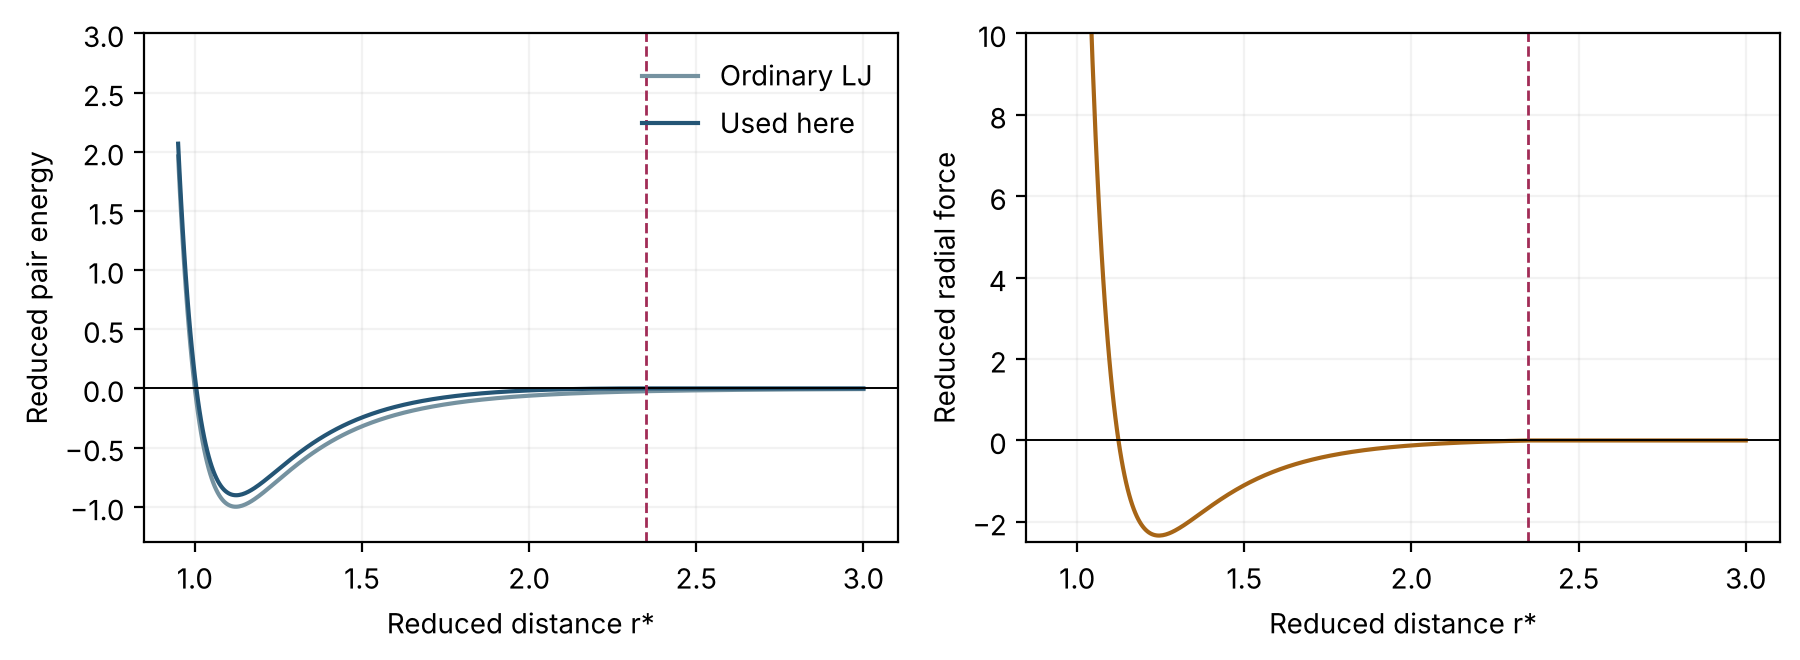

In [2]:
# Name a scalar-or-array function for the ordinary Lennard-Jones pair energy.
def lj_energy(r):
    # Compute the inverse sixth power once and reuse it in the twelfth-power term.
    inverse_sixth = (1.0 / r)**6
    # Subtract the attractive inverse-sixth term from the repulsive inverse-twelfth term.
    return 4.0 * (inverse_sixth**2 - inverse_sixth)

# Define the radial force as minus the derivative of the ordinary LJ energy.
def lj_radial_force(r):
    # Combine the repulsive and attractive radial-force powers for reduced units.
    return 24.0 * (2.0 / r**13 - 1.0 / r**7)

# Cache the unshifted energy at the fixed cutoff before integrating.
u_cut = lj_energy(cutoff)
# Cache the radial force at that same cutoff for the shifted-force correction.
f_cut = lj_radial_force(cutoff)
# Sample positive radii on both sides of the cutoff to draw a comparison.
distances = np.linspace(0.95, 3.0, 450)
# Apply the shifted energy below the cutoff and zero outside it.
shifted = np.where(distances < cutoff,
                   # Subtract the cutoff energy and add the linear force-shift term.
                   lj_energy(distances)-u_cut+(distances-cutoff)*f_cut, 0.0)
# Apply the shifted radial force below the cutoff and zero outside it.
shifted_force = np.where(distances < cutoff,
                         # Subtract the cached cutoff force so the inside limit approaches zero.
                         lj_radial_force(distances)-f_cut, 0.0)

# Place energy and radial force beside each other for comparison.
fig, axes = plt.subplots(1, 2, figsize=(9.1, 3.4))
# Draw the ordinary potential as the reference interaction.
axes[0].plot(distances, lj_energy(distances), color='#7592a0', label='Ordinary LJ')
# Overlay the potential actually used by this simulation.
axes[0].plot(distances, shifted, color='#245575', label='Used here')
# Restrict the energy view and label its reduced-distance axis.
axes[0].set(ylim=(-1.3, 3.0), xlabel='Reduced distance r*',
            # Identify the vertical axis as reduced pair energy.
            ylabel='Reduced pair energy')
# Distinguish the two potentials using their legend labels.
axes[0].legend(frameon=False)
# Plot the shifted radial force to check its cutoff behavior.
axes[1].plot(distances, shifted_force, color='#a76516')
# Restrict the force panel and label the reduced-distance axis.
axes[1].set(ylim=(-2.5, 10), xlabel='Reduced distance r*',
            # Identify the second vertical axis as reduced radial force.
            ylabel='Reduced radial force')
# Apply the same reference guides to both plot panels.
for ax in axes:
    # Mark zero to show where energy or force changes sign.
    ax.axhline(0, color='black', linewidth=0.7)
    # Mark the selected cutoff distance with a vertical dashed line.
    ax.axvline(cutoff, color='#a12c56', linestyle='--', linewidth=1)
    # Add light gridlines without obscuring the two curves.
    ax.grid(alpha=0.16)
# Fit labels within the figure area before rendering.
fig.tight_layout()
# Display both panels in the executed notebook.
plt.show()


## 2. Initial state and the array of particle pairs

We begin on a $4\times4\times4$ grid with spacing $L/4$. The grid prevents a large initial repulsive force; it is a preparation device, not a prediction of a crystal. Naively placing particles at uniformly random positions could create near-overlaps, making the $r^{-12}$ repulsion enormous and forcing a smaller time step or an additional overlap-rejection procedure. A lattice is inexpensive and predictable, although it introduces artificial order that the preparation stage must help remove. Random initial velocity components come from a seeded NumPy generator. We remove the mean velocity (zero total momentum for equal masses), then rescale once so that the initial kinetic temperature is the chosen target.

In three dimensions, $K=\tfrac12\sum_i|\mathbf v_i|^2$. Removing three centre-of-mass velocity components leaves $3N-3$ degrees of freedom. The instantaneous kinetic-temperature estimate is therefore $T^*_{\rm kin}=2K/(3N-3)$. The separate pressure calculation later uses **the actual kinetic energy**, rather than replacing it with a fixed target temperature.

**Efficiency focus 2 — start safely.** A single very close pair can dominate the first force calculation. The small fixed-seed comparison after initialization measures the closest pair in the lattice and in one naive random placement. It does not use the random positions for the simulation.


In [3]:
# Space the sites evenly to avoid an initially overlapping pair.
spacing = box_length / particles_per_side
# Collect the three coordinates of each site in a floating-point array.
initial_positions = np.array([
    # Place a site at the centre of each grid cell.
    [(ix+0.5)*spacing, (iy+0.5)*spacing, (iz+0.5)*spacing]
    # Advance through the four z layers.
    for iz in range(particles_per_side)
    # Advance through the four y rows within each layer.
    for iy in range(particles_per_side)
    # Advance through the four x positions within each row.
    for ix in range(particles_per_side)
# Finish the array conversion with coordinates stored as floats.
], dtype=float)

# Separate the kinetic-energy calculation for reuse in several stages.
def kinetic_energy(velocities):
    # Sum squared velocity components and multiply by one-half for mass one.
    return 0.5 * float(np.sum(velocities**2))

# Define the instantaneous temperature estimator for this 3D system.
def kinetic_temperature(velocities):
    # Subtract three centre-of-mass degrees of freedom from 3N.
    return 2.0 * kinetic_energy(velocities) / (3*len(velocities)-3)

# Construct seeded velocities without modifying any global random state.
def initial_velocities(seed):
    # Create a generator local to the function for repeatability.
    generator = np.random.default_rng(seed)
    # Draw one normal random velocity component for each coordinate.
    velocities = generator.normal(size=(n_particles, 3))
    # Remove net translation by subtracting the mean velocity vector.
    velocities -= velocities.mean(axis=0)
    # Scale all velocities to the requested initial kinetic temperature.
    velocities *= math.sqrt(target_temperature / kinetic_temperature(velocities))
    # Return the prepared velocity array to the caller.
    return velocities

# Generate the seeded initial velocities once for this trial.
initial_velocity = initial_velocities(random_seed)
# Show that positions have one row per particle and three columns.
print('Position array shape:', initial_positions.shape)
# Inspect one grid point to make the coordinate convention concrete.
print('Particle 0 coordinates:', np.round(initial_positions[0], 3))
# Verify the one-time velocity rescaling reached the requested temperature.
print('Starting T*:', round(kinetic_temperature(initial_velocity), 6))
# Verify that subtracting the mean removed the net momentum.
print('Net momentum:', np.round(initial_velocity.sum(axis=0), 12))

# Define a diagnostic that compares nearest distinct periodic images.
def closest_pair_distance(points):
    # Broadcast point coordinates to form all ordered pair displacements.
    differences = points[:, None, :] - points[None, :, :]
    # Use minimum-image displacements across periodic boundaries.
    differences -= box_length*np.rint(differences/box_length)
    # Sum the three squared components before taking any square root.
    squared = np.sum(differences**2, axis=2)
    # Exclude zero-distance self-pairs when finding the nearest neighbor.
    np.fill_diagonal(squared, np.inf)
    # Take one root after finding the smallest squared pair separation.
    return float(np.sqrt(np.min(squared)))

# Draw an independent fixed-seed random placement for comparison only.
trial_random_positions = np.random.default_rng(73).uniform(
    # Fill all three coordinates of every trial particle within the box.
    0, box_length, size=(n_particles, 3))
# Report the predictable nearest separation on the constructed grid.
print('Closest lattice pair:', f'{closest_pair_distance(initial_positions):.3f}')
# Report the nearest separation in this particular random trial.
print('Closest naive random pair:',
      # Complete the displayed distance without simulating the random trial.
      f'{closest_pair_distance(trial_random_positions):.3f}')


Position array shape: (64, 3)
Particle 0 coordinates: [0.61 0.61 0.61]
Starting T*: 0.85
Net momentum: [0. 0. 0.]
Closest lattice pair: 1.221
Closest naive random pair: 0.184


The two distances refer to one reproducible trial, not to a general guarantee about random arrangements. A different seed could produce a different nearest pair. The random positions are used only for this comparison: a near overlap would fail the force calculation's safety check, so we do not advance those positions in time. This is a useful example of checking an input before running an expensive calculation.


Forces need all differences $\mathbf r_i-\mathbf r_j$. The expression `positions[:, None, :] - positions[None, :, :]` produces an $(N,N,3)$ array: entry `[i, j]` is a three-component pair displacement. The diagonal contains self-pairs and must be ignored. A symmetric array contains both $(i,j)$ and $(j,i)$; force summation uses both, whereas potential energy and the pair virial divide their totals by two. This is the array version of the nested pair loop in the preliminary notebook.

The nearest-image calculation subtracts $L\,\mathrm{rint}(\mathbf d/L)$ component by component. It does not alter the stored coordinates. A conditional check still protects against accidentally overlapping *distinct* particles. This full pair-array calculation uses work and memory proportional to $N^2$; large-scale programs generally use neighbour lists instead.

**Efficiency focus 3 — filter before the expensive operation.** Find `squared_distance`, `active`, `inverse_r6`, `inverse_r12` and `distance` in the function below. Explain why `np.sqrt` is called on `squared_distance[active]`, and why this is different from saying that the whole force calculation needs no square roots. Also identify the price of forming an $(N,N,3)$ array in memory.


In [4]:
# A three-particle example makes the new array shape visible.
# Choose three points with known differences to illustrate broadcasting.
toy = np.array([[1., 1., 1.], [2., 1., 1.], [1., 3., 1.]])
# Form every ordered three-dimensional displacement in one array operation.
toy_differences = toy[:, None, :] - toy[None, :, :]
# Verify the resulting axes represent particle, particle and coordinate.
print('Toy array shape:', toy_differences.shape)
# Inspect the displacement from the second point to the first.
print('Displacement [0, 1]:', toy_differences[0, 1])
# Verify reversing a pair reverses the sign of its displacement.
print('Displacement [1, 0]:', toy_differences[1, 0])
# Show why a particle paired with itself must later be excluded.
print('Self-displacement [1, 1]:', toy_differences[1, 1])


Toy array shape: (3, 3, 3)
Displacement [0, 1]: [-1.  0.  0.]
Displacement [1, 0]: [1. 0. 0.]
Self-displacement [1, 1]: [0. 0. 0.]


In [5]:
# Give one function responsibility for pair forces, energy and virial.
def pair_quantities(positions):
    # Broadcast positions into every ordered displacement vector.
    displacement = positions[:, None, :] - positions[None, :, :]
    # Replace each displacement with its nearest periodic image.
    displacement -= box_length * np.rint(displacement / box_length)
    # Compute squared distances without a square root.
    squared_distance = np.sum(displacement**2, axis=2)
    # Mark the diagonal self-pairs that must never interact.
    self_pair = np.eye(len(positions), dtype=bool)
    # Detect a dangerous overlap only among distinct particles.
    if np.any((squared_distance < 0.16) & ~self_pair):
        # Stop before a near-zero separation creates enormous repulsion.
        raise ValueError('Two distinct particles are dangerously close.')
    # Compare squared distances with squared cutoff before any square root.
    active = (squared_distance < cutoff**2) & ~self_pair

    # Allocate inverse-distance storage with zeros for inactive pairs.
    inverse_r2 = np.zeros_like(squared_distance)
    # Divide only for active pairs, never for diagonal zeros.
    inverse_r2[active] = 1.0 / squared_distance[active]
    # Form r^-6 by cubing r^-2; no root is needed for the LJ core.
    inverse_r6 = inverse_r2**3
    # Square r^-6 to obtain r^-12 with one multiplication.
    inverse_r12 = inverse_r6**2
    # Allocate distances only to apply the force-shift correction.
    distance = np.zeros_like(squared_distance)
    # Take a square root once per active pair for that correction.
    distance[active] = np.sqrt(squared_distance[active])

    # Start a scalar force coefficient matrix at zero.
    radial_coefficient = np.zeros_like(squared_distance)
    # Fill coefficients only where the interaction is active.
    radial_coefficient[active] = (
        # Build the standard LJ force coefficient from inverse powers.
        24.0*(2.0*inverse_r12[active]-inverse_r6[active])
        # Subtract the force-at-cutoff correction divided by distance.
        * inverse_r2[active] - f_cut/distance[active])
    # Multiply each scalar coefficient by its displacement vector.
    pair_force = radial_coefficient[:, :, None] * displacement
    # Sum all forces acting on each particle; opposite pairs cancel globally.
    forces = pair_force.sum(axis=1)

    # Start pair-energy storage at zero for inactive pairs.
    shifted_pair_energy = np.zeros_like(squared_distance)
    # Calculate the energy only for pairs within the cutoff.
    shifted_pair_energy[active] = (
        # Subtract the constant energy at the cutoff.
        4.0*(inverse_r12[active]-inverse_r6[active]) - u_cut
        # Add the linear correction that makes the force continuous.
        + (distance[active]-cutoff)*f_cut)
    # Divide the ordered-pair energy sum by two to count each pair once.
    potential = 0.5 * float(shifted_pair_energy.sum())
    # Likewise count each displacement-dot-force virial contribution once.
    pair_virial = 0.5 * float(np.sum(displacement*pair_force))
    # Return the three physical quantities needed by the integrator.
    return forces, potential, pair_virial

# Evaluate the initial lattice forces, pair energy and virial once.
force0, potential0, virial0 = pair_quantities(initial_positions)
# Display a value students can inspect and compare.
print('Initial U*:', round(potential0, 4))
# Display a value students can inspect and compare.
print('Initial pair virial:', round(virial0, 4))
# Display a value students can inspect and compare.
print('Net internal force:', np.round(force0.sum(axis=0), 12))


Initial U*: -178.6604
Initial pair virial: -853.837
Net internal force: [ 0. -0. -0.]


### Tests before the full run

The force on two particles must be equal and opposite. We can also check the *derivative* of the implemented pair energy numerically: for two particles separated along $x$, $F_x\approx-[U(r+h)-U(r-h)]/(2h)$. This is a useful independent check of the sign and the cutoff correction. We test a separation well inside the cutoff and a separation exactly at the cutoff. `assert` stops the notebook if an expectation is violated.


In [6]:
# Define a controlled two-particle input for testing pair calculations.
def two_particle_result(separation):
    # Place the particles along x so the expected force has one component.
    points = np.array([[1.0+separation, 1.0, 1.0], [1.0, 1.0, 1.0]])
    # Reuse the production pair function for the independent numerical check.
    return pair_quantities(points)

# Choose a separation inside the cutoff and a small finite-difference offset.
r_test, h = 1.25, 1e-5
# Evaluate the analytic x force at the unperturbed separation.
f_test, _, _ = two_particle_result(r_test)
# Evaluate potential energy just above the test separation.
_, u_plus, _ = two_particle_result(r_test+h)
# Evaluate potential energy just below the test separation.
_, u_minus, _ = two_particle_result(r_test-h)
# Approximate minus the derivative of energy by a centered difference.
finite_difference_force = -(u_plus-u_minus)/(2*h)
# Evaluate both energy and force exactly at the chosen cutoff.
f_at_cut, u_at_cut, _ = two_particle_result(cutoff)

# Display the computed x force to seven decimal places.
print('Analytical force on particle 0:', f'{f_test[0,0]:.7f}')
# Display the independent finite-difference estimate alongside it.
print('Finite-difference force:       ', f'{finite_difference_force:.7f}')
# Confirm opposite pair forces sum to a zero vector.
print('Net pair force:', np.round(f_test.sum(axis=0), 12))
# Introduce the continuity check at the cutoff.
print('At cutoff: potential and force norms:',
      # Complete the display with cutoff energy and force magnitude.
      round(u_at_cut, 12), round(np.linalg.norm(f_at_cut), 12))
# Require the analytic force to agree with the energy derivative.
assert np.isclose(f_test[0,0], finite_difference_force, atol=1e-6)
# Require Newton third-law cancellation for the pair.
assert np.allclose(f_test.sum(axis=0), 0, atol=1e-12)
# Require exactly zero values for pairs outside the active range.
assert u_at_cut == 0 and np.allclose(f_at_cut, 0)


Analytical force on particle 0: -2.3344201
Finite-difference force:        -2.3344201
Net pair force: [0. 0. 0.]
At cutoff: potential and force norms: 0.0 0.0


## 3. Velocity Verlet and two phases

For each time step $\Delta t$, velocity Verlet makes a half velocity update, a full position update, computes the new forces, and finishes the velocity update:

$$\mathbf v_{n+1/2}=\mathbf v_n+\tfrac12\Delta t\,\mathbf F_n,\quad
\mathbf r_{n+1}=\mathbf r_n+\Delta t\,\mathbf v_{n+1/2},\quad
\mathbf v_{n+1}=\mathbf v_{n+1/2}+\tfrac12\Delta t\,\mathbf F_{n+1}.$$

Here mass is one. We retain **unwrapped** coordinates separately for displacement analysis, but pass wrapped positions to the force calculation. The intermediate half-step velocity is held in the **same velocity array**; the position, unwrapped position and force arrays are also updated in place. We need only the current state, not separate arrays for every time step. The half-step formula itself does **not** guarantee a RAM saving; the saving comes from this rolling-state implementation and from recording a few selected snapshots rather than an entire trajectory. NumPy still creates temporary pair arrays of size proportional to $N^2$ during a force calculation. The preparation stage rescales velocities every 20 steps to keep the system near the chosen temperature. This is a simple numerical preparation procedure; it is **not** a rigorous canonical-ensemble thermostat and does not conserve energy while rescaling. We therefore start a new, unthermostatted production history after preparation. Only production data are used in the reported means and energy check.

**Efficiency focus 4 — reuse state.** In `verlet_step`, `+=` and `[:] =` change existing arrays. Trace one step on paper: the velocity array first holds $\mathbf v_{n+1/2}$ and then $\mathbf v_{n+1}$. Neither version of the formula requires retaining the entire earlier trajectory. A production run begins from fresh copies of the prepared state so that a second run does not change the first.


In [7]:
# Advance one time step while reusing four persistent state arrays.
def verlet_step(positions, unwrapped, velocities, forces, dt):
    # Reuse the velocity array for the first half-step.
    velocities += 0.5*dt*forces
    # Accumulate motion before wrapping so boundary crossings remain known.
    unwrapped += dt*velocities
    # Overwrite wrapped positions for the next force evaluation.
    positions[:] = unwrapped % box_length
    # Compute new forces only after positions have advanced.
    new_forces, potential, virial = pair_quantities(positions)
    # Finish the velocity update in the same array.
    velocities += 0.5*dt*new_forces
    # Copy new forces into the reusable force array.
    forces[:] = new_forces
    # Return two scalar diagnostics without copying the particle state.
    return potential, virial

# Copy initial positions so the reference grid remains unchanged.
positions = initial_positions.copy()
# Start unwrapped coordinates from the same locations.
unwrapped = positions.copy()
# Copy velocities to preserve the seeded reference array.
velocities = initial_velocity.copy()
# Evaluate initial forces and diagnostic quantities.
forces, potential, virial = pair_quantities(positions)
# Store the initial preparation temperature in a list.
preparation_temperature = [kinetic_temperature(velocities)]

# Advance only the limited preparation stage in this loop.
for step in range(1, preparation_steps+1):
    # Call one velocity-Verlet step on the rolling state.
    potential, virial = verlet_step(positions, unwrapped, velocities,
                                   # Pass the existing force array and chosen time increment.
                                   forces, time_step)
    # Select every twentieth step for simple velocity rescaling.
    if step % 20 == 0:
        # Rescale in place; this intentionally changes the energy.
        velocities *= math.sqrt(target_temperature / kinetic_temperature(velocities))
    # Append a scalar temperature, not a full position array.
    preparation_temperature.append(kinetic_temperature(velocities))

# Freeze a copy of the prepared state for independent production runs.
prepared_state = (positions.copy(), unwrapped.copy(), velocities.copy())
# Display a value students can inspect and compare.
print('Last preparation T*:', round(preparation_temperature[-1], 5))
# Display a value students can inspect and compare.
print('Range during preparation:',
      # Complete the preceding multi-line display or data expression.
      f'{min(preparation_temperature):.3f} to {max(preparation_temperature):.3f}')


Last preparation T*: 0.85
Range during preparation: 0.644 to 0.985


The production function begins with **copies** of the prepared arrays. Without `.copy()`, an edit to one array could unexpectedly affect another run. The result is a dictionary whose keys name the time series. Lists of **scalar** observables are appended at each step and converted into arrays afterwards. Every tenth production step, an `if` condition stores a position snapshot for pair-structure analysis. The rolling state is overwritten in each step. The same function can be called again with a smaller time step for a numerical check.

**Efficiency focus 5 — store what the question needs.** Temperature, energy and pressure are a few numbers per step. An RDF needs some particle configurations, but not necessarily every configuration. The byte counts following the run compare these two choices for **position storage only**.


In [8]:
# Encapsulate production so the same prepared state can be rerun.
def production_run(prepared, dt, steps, sample_every=10):
    # Copy each state array to prevent cross-run modification.
    positions, unwrapped, velocities = (array.copy() for array in prepared)
    # Keep the unwrapped starting point for displacement measurements.
    origin = unwrapped.copy()
    # Initialize force, energy and virial at production time zero.
    forces, potential, virial = pair_quantities(positions)

    # Store scalar observables in lists indexed by measurement time.
    records = {'time': [], 'K': [], 'U': [], 'E': [],
               # Complete the dictionary of scalar time series.
               'T': [], 'P': [], 'MSD': []}
    # Keep only selected full position snapshots for structural analysis.
    structure_snapshots = []

    # Include the initial measurement and each production step.
    for step in range(steps+1):
        # Calculate the actual kinetic energy from current velocities.
        kinetic = kinetic_energy(velocities)
        # Convert kinetic energy to the three-dimensional temperature estimator.
        temperature = kinetic_temperature(velocities)
        # Evaluate pressure using actual kinetic energy and the pair virial.
        pressure = (2.0*kinetic + virial)/(3.0*volume)
        # Measure displacement from the unwrapped production origin.
        displacement = unwrapped-origin
        # Average squared displacements over all particles.
        msd = float(np.mean(np.sum(displacement**2, axis=1)))
        # Pair each named observable with its current scalar value.
        for key, value in (('time', step*dt), ('K', kinetic),
                           # Record potential and total energy at the same instant.
                           ('U', potential), ('E', kinetic+potential),
                           # Include temperature, pressure and displacement in the record.
                           ('T', temperature), ('P', pressure), ('MSD', msd)):
            # Append one scalar to the list belonging to this name.
            records[key].append(value)
        # Save an occasional snapshot, but skip the initial frame.
        if step > 0 and step % sample_every == 0:
            # Copy coordinates because the rolling position array will change.
            structure_snapshots.append(positions.copy())
        # After measuring the last state, avoid an extra integration step.
        if step == steps:
            # Exit the loop at the requested final time.
            break
        # Advance the rolling state in place for the next observation.
        potential, virial = verlet_step(positions, unwrapped, velocities,
                                       # Supply force and time increment to finish this step.
                                       forces, dt)

    # Convert small scalar histories into arrays for plots and statistics.
    return {**{key: np.asarray(values) for key, values in records.items()},
            # Return selected snapshots and one final position copy.
            'snapshots': structure_snapshots, 'final_positions': positions.copy(),
            # Retain the numerical settings alongside the data.
            'dt': dt, 'steps': steps}

# Launch the isolated production stage from the prepared state.
production = production_run(prepared_state, time_step, production_steps)
# Display a value students can inspect and compare.
print('Recorded production instants:', len(production['time']))
# Display a value students can inspect and compare.
print('Structure snapshots:', len(production['snapshots']))
# Display a value students can inspect and compare.
print('Production time span:', production['time'][0], 'to', production['time'][-1])
# Estimate position-storage cost if every time step were saved.
all_frames_bytes = (production_steps+1)*initial_positions.nbytes
# Count bytes actually retained in the selected snapshots.
saved_frames_bytes = sum(frame.nbytes for frame in production['snapshots'])
# Display a value students can inspect and compare.
print('Position bytes if every step were saved:', all_frames_bytes)
# Display a value students can inspect and compare.
print('Position bytes for selected snapshots: ', saved_frames_bytes)


Recorded production instants: 901
Structure snapshots: 90
Production time span: 0.0 to 2.7
Position bytes if every step were saved: 1383936
Position bytes for selected snapshots:  138240


The two printed byte counts compare **position snapshots only**. Storing one frame in every production step would use roughly ten times the snapshot storage in this particular run. Scalar histories and the temporary $(N,N,3)$ pair-displacement array use additional memory. The half-step does not provide this reduction by magic: in-place state updates and selective recording do.


The two pictures below show the starting grid and a later wrapped configuration. Each dot is a point particle; marker size is only for visibility. A particle shown near one edge may have crossed the periodic boundary several times, so these pictures cannot replace the unwrapped displacement calculation.


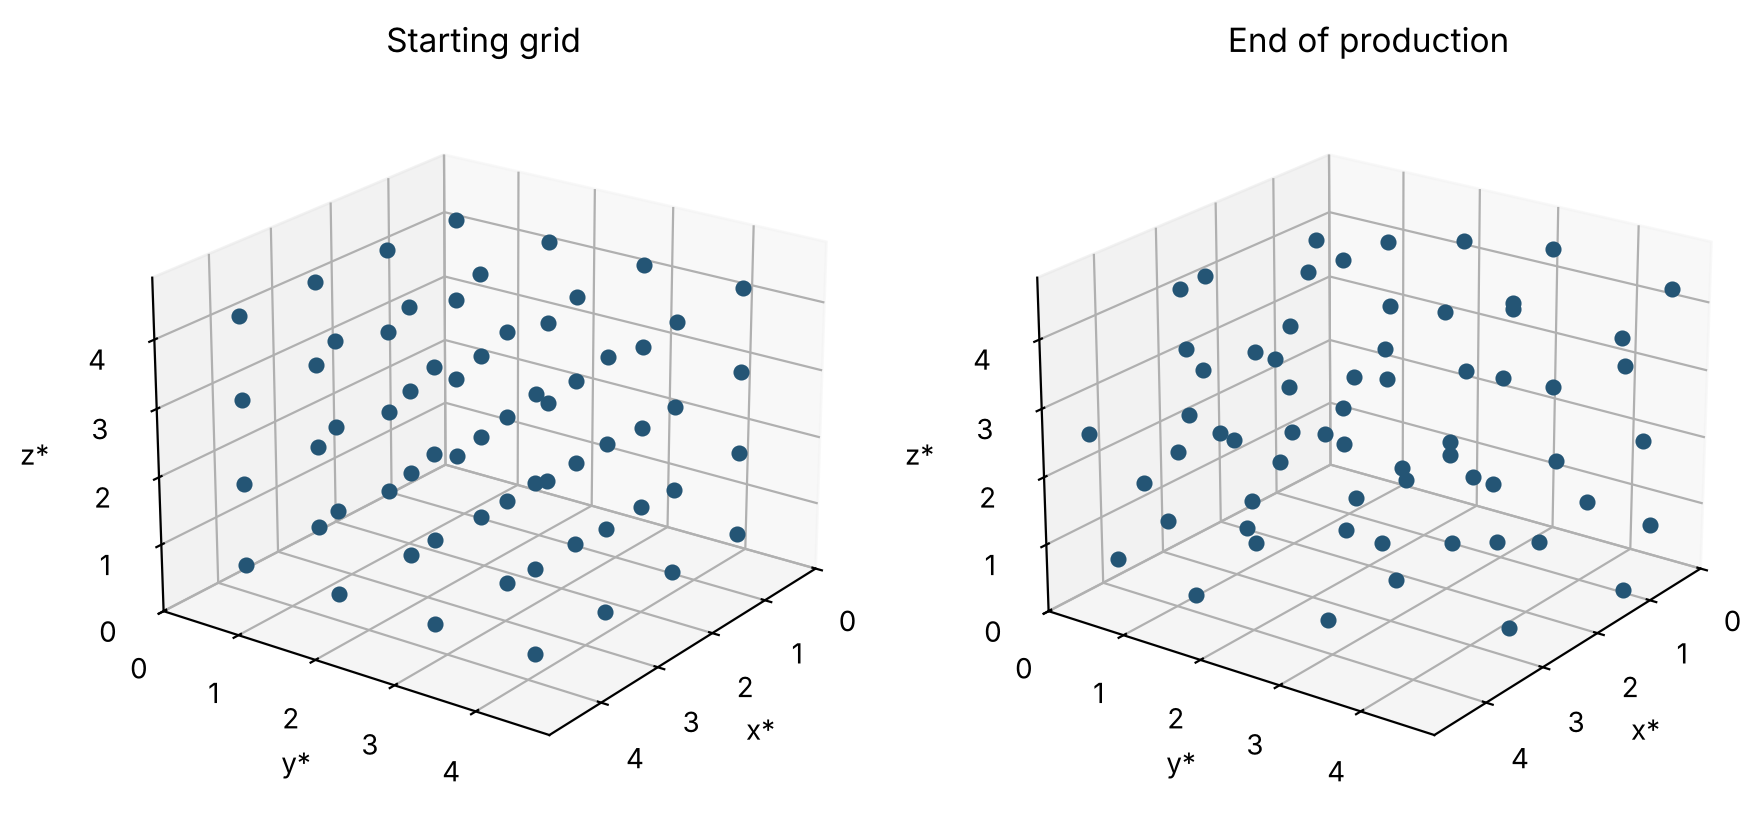

In [9]:
# Create a two-panel three-dimensional view of particle configurations.
fig = plt.figure(figsize=(9.0, 4.2))
# Iterate over the initial and final configurations with panel labels.
for panel, (points, title) in enumerate(((initial_positions, 'Starting grid'),
                                         # Supply the last saved production coordinates for the second panel.
                                         (production['final_positions'],
                                          # Finish the panel pair and begin numbering axes at one.
                                          'End of production')), start=1):
    # Allocate a separate three-dimensional axis for each configuration.
    ax = fig.add_subplot(1, 2, panel, projection='3d')
    # Plot x, y and z coordinates in their respective columns.
    ax.scatter(points[:, 0], points[:, 1], points[:, 2],
               # Use small opaque markers so all 64 points remain visible.
               s=23, color='#245575', depthshade=False)
    # Keep both coordinate ranges within the same periodic-box bounds.
    ax.set(xlim=(0, box_length), ylim=(0, box_length), zlim=(0, box_length),
           # Label the three reduced axes and the configuration being shown.
           xlabel='x*', ylabel='y*', zlabel='z*', title=title)
    # Apply an identical viewing angle to both panels for comparison.
    ax.view_init(elev=22, azim=36)
# Keep three-dimensional axis labels within the page margins.
fig.tight_layout()
# Display the start-versus-finish comparison.
plt.show()


## 4. Thermodynamic time series

The production plots show exchange between kinetic energy $K$ and pair potential energy $U$, while the total $E=K+U$ should be nearly constant. The instantaneous reduced pressure is calculated from the trace of the virial expression

$$P^*=\frac{2K+W}{3V},\qquad W=\sum_{i<j}\mathbf r_{ij}\cdot\mathbf F_{ij}.$$

Here $\mathbf r_{ij}$ is the nearest-image displacement and $\mathbf F_{ij}$ is the corresponding shifted force; `pair_quantities` counts each unordered pair once in $W$. Pressure may be positive or negative in a small finite system and fluctuates appreciably. It refers to this **truncated, force-shifted model**; no long-range or finite-size corrections are included. Temperature and pressure are kinetic/virial estimators, not direct measurements with laboratory instruments.


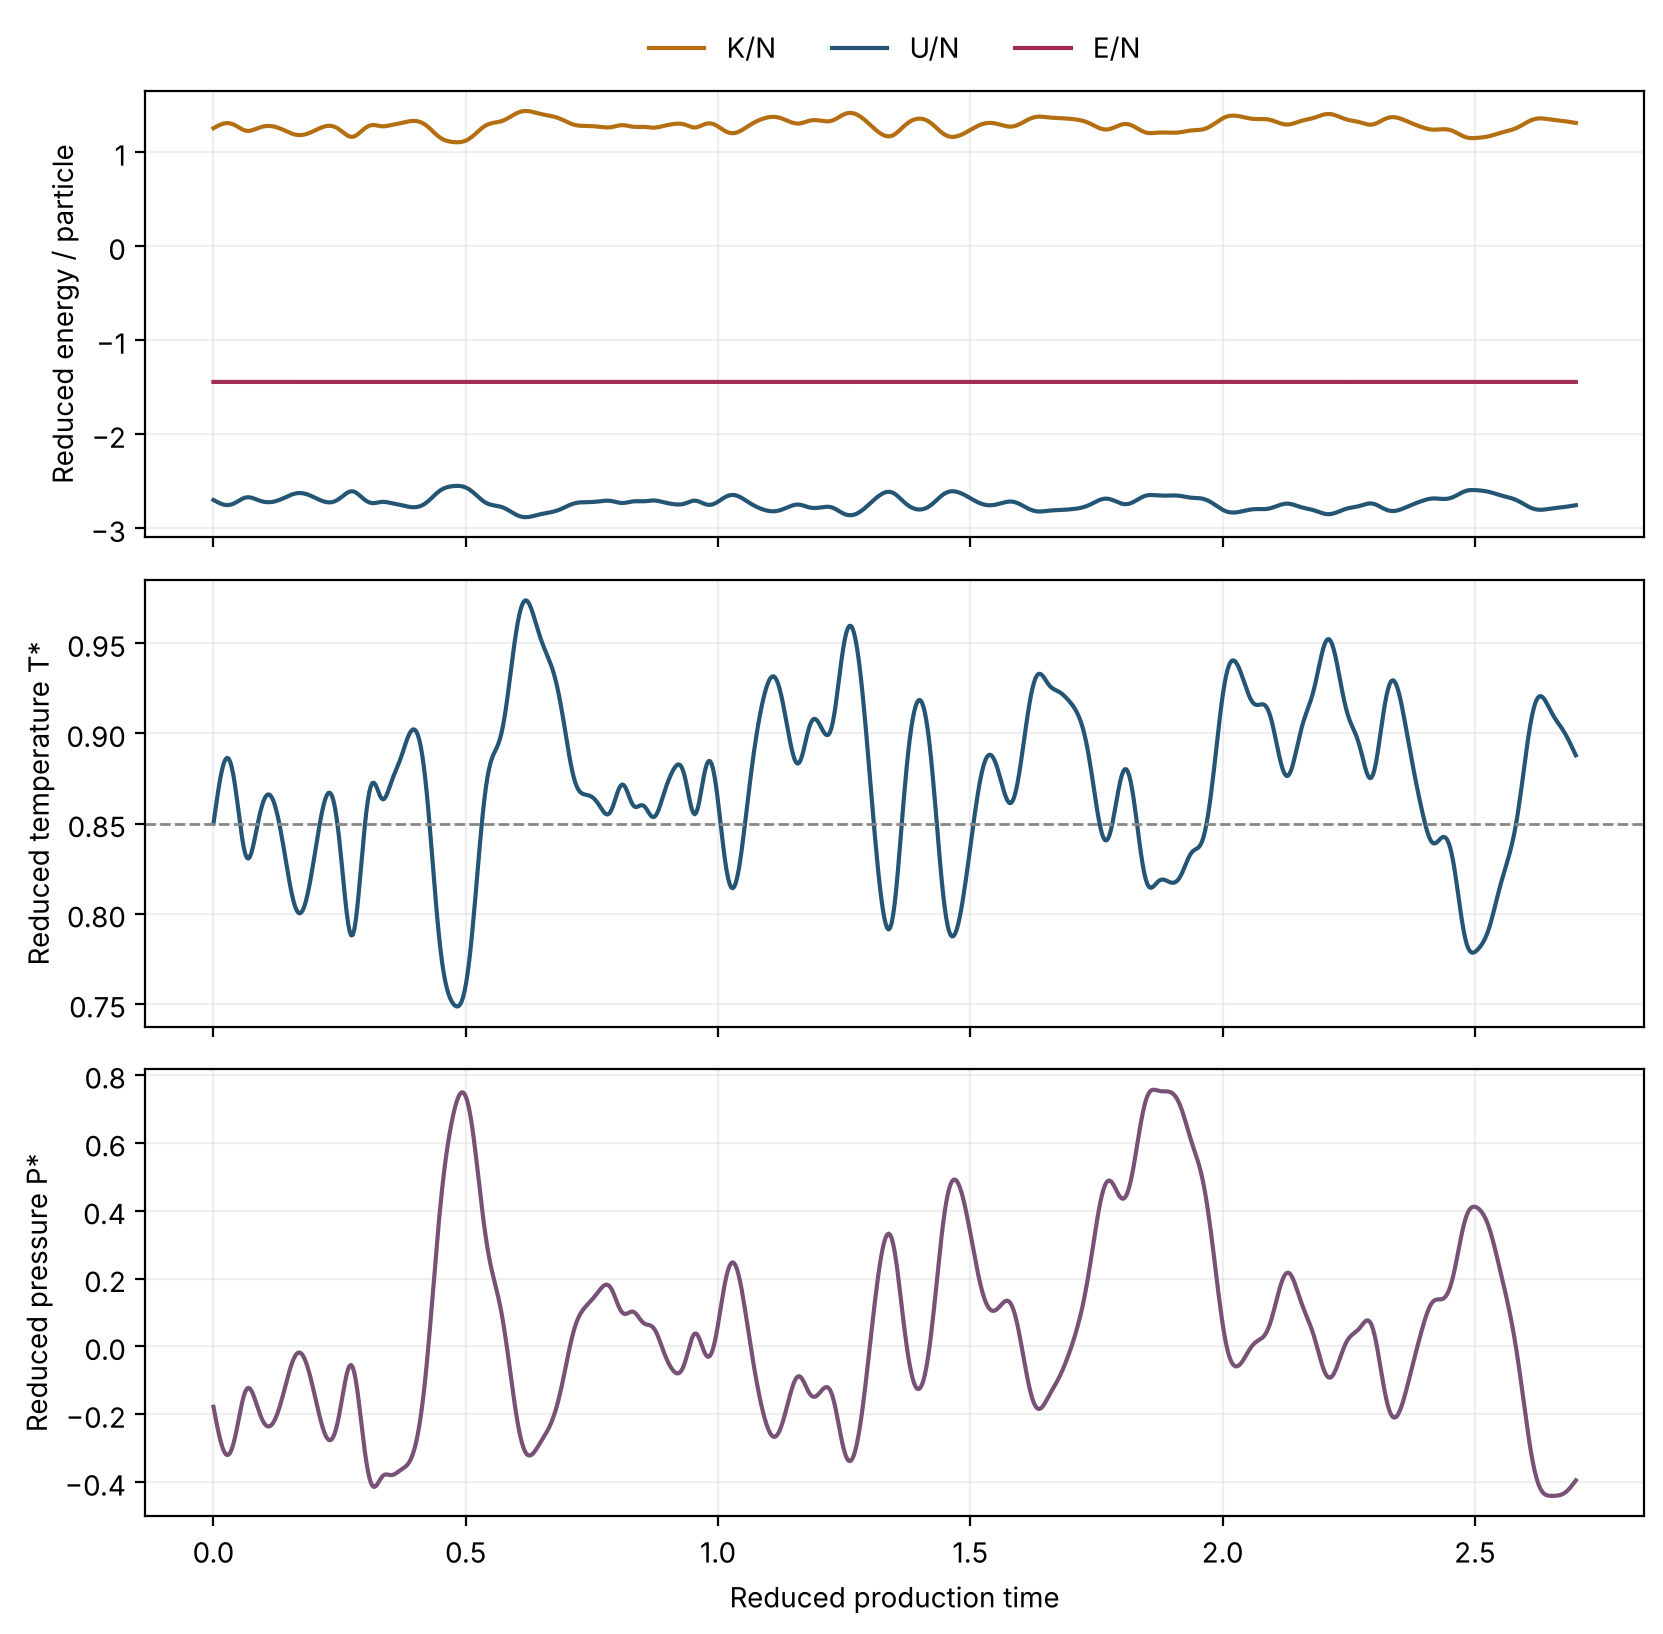

In [10]:
# Create aligned time-series panels with one common time axis.
fig, axes = plt.subplots(3, 1, figsize=(8.5, 8.2), sharex=True)
# Plot kinetic energy divided by particle count.
axes[0].plot(production['time'], production['K']/n_particles,
             # Identify the kinetic-energy curve as K per particle.
             color='#b46f12', label='K/N')
# Plot pair potential energy on the same per-particle scale.
axes[0].plot(production['time'], production['U']/n_particles,
             # Identify the potential-energy curve as U per particle.
             color='#245575', label='U/N')
# Add total energy to expose numerical drift over time.
axes[0].plot(production['time'], production['E']/n_particles,
             # Identify the total-energy curve as E per particle.
             color='#a12c56', label='E/N')
# Label the first panel with its reduced energy units.
axes[0].set_ylabel('Reduced energy / particle')
# Display all three energy-curve labels above the panel.
axes[0].legend(ncol=3, frameon=False, loc='upper center',
               # Move the legend clear of the changing energy curves.
               bbox_to_anchor=(0.5, 1.19))
# Plot kinetic temperature measured from instantaneous velocities.
axes[1].plot(production['time'], production['T'], color='#245575')
# Draw the preparation target as a reference, not a production thermostat.
axes[1].axhline(target_temperature, color='#888', linestyle='--', linewidth=1)
# Label the temperature panel in reduced units.
axes[1].set_ylabel('Reduced temperature T*')
# Plot pressure calculated from kinetic energy and pair virial.
axes[2].plot(production['time'], production['P'], color='#785177')
# Label production time and reduced pressure on the last panel.
axes[2].set(xlabel='Reduced production time', ylabel='Reduced pressure P*')
# Apply the same grid treatment to all three linked panels.
for ax in axes:
    # Use unobtrusive lines to help follow fluctuations over time.
    ax.grid(alpha=0.2)
# Prevent the panel labels and legend from overlapping.
fig.tight_layout()
# Display the energy, temperature and pressure histories.
plt.show()


### A compact numerical report

We compute full-production descriptive statistics, then five consecutive **block means** of temperature and pressure. The blocks expose some time variation that a single overall mean conceals. Their standard deviation is a descriptive measure of how these five averages differ; it is **not** a confidence interval. Adjacent molecular-dynamics samples are correlated, five blocks are few, and this run is short. These numbers are not converged equilibrium material properties.

For energy conservation, we measure the largest production deviation from the first production energy and divide by $\max(|E(0)|,1)$. This arbitrary scale avoids division by zero. It is a numerical diagnostic, not a statistical uncertainty.


In [11]:
# Give the block-means calculation a reusable name.
def five_block_means(values):
    # Split the time series into five contiguous blocks and average each.
    return [statistics.mean(block) for block in np.array_split(values, 5)]

# Exclude production time zero and summarize temperature by blocks.
temperature_blocks = five_block_means(production['T'][1:])
# Apply the same block partition to the pressure series.
pressure_blocks = five_block_means(production['P'][1:])
# Use the first production energy as the conservation reference.
e0 = production['E'][0]
# Take the largest absolute energy deviation and express it as a percent.
energy_error_percent = (100*np.max(np.abs(production['E']-e0))
                        # Avoid division by a nearly zero initial total energy.
                        / max(abs(e0), 1.0))

# Collect clearly labelled results in a dictionary.
report = {
    # Record the elapsed duration of the production stage.
    'production_time': production['time'][-1],
    # Compute the full-production mean of kinetic-temperature samples.
    'temperature_mean': statistics.mean(production['T'][1:]),
    # Compute sample SD, a spread measure rather than an error bar.
    'temperature_sample_SD': statistics.stdev(production['T'][1:]),
    # Compute the full-production mean pressure.
    'pressure_mean': statistics.mean(production['P'][1:]),
    # Compute its sample SD, retaining the sign of the mean separately.
    'pressure_sample_SD': statistics.stdev(production['P'][1:]),
    # Normalize the average pair energy by particle number.
    'mean_U_per_particle': statistics.mean(production['U'][1:])/n_particles,
    # Normalize average total energy in the same way.
    'mean_E_per_particle': statistics.mean(production['E'][1:])/n_particles,
    # Include the numerical energy diagnostic.
    'max_energy_deviation_percent': energy_error_percent,
# Close the dictionary after all results are named.
}
# Iterate through name-value pairs without hard-coding print statements.
for name, value in report.items():
    # Display a value students can inspect and compare.
    print(f'{name:33s} {value: .5f}')
# Display a value students can inspect and compare.
print('Five temperature block means:', np.round(temperature_blocks, 3))
# Display a value students can inspect and compare.
print('Five pressure block means:   ', np.round(pressure_blocks, 3))


production_time                    2.70000
temperature_mean                   0.87167
temperature_sample_SD              0.04620
pressure_mean                      0.04569
pressure_sample_SD                 0.28399
mean_U_per_particle               -2.73009
mean_E_per_particle               -1.44301
max_energy_deviation_percent       0.01306
Five temperature block means: [0.839 0.883 0.88  0.881 0.876]
Five pressure block means:    [-0.062  0.011  0.02   0.272 -0.013]


## 5. Pair structure: the radial distribution function

The radial distribution function $g(r)$ asks whether other particles are more or less common at distance $r$ from a particle than they would be for uniformly distributed positions. We histogram **unordered** pair distances in the saved production snapshots. For a shell between $r_a$ and $r_b$, its volume is $\frac{4\pi}{3}(r_b^3-r_a^3)$. For $N(N-1)/2$ possible unordered pairs in volume $V$, the uniform-position reference count per snapshot is

$$C_{\mathrm{ref}}=\frac{N(N-1)}{2}\frac{V_{\mathrm{shell}}}{V},\qquad
g(r)\approx\frac{\text{count accumulated in shell}}{\text{number of snapshots}\times C_{\mathrm{ref}}}.$$

We use $r<L/2$, where the entire spherical shell fits inside the minimum-image region. A small $g(r)$ near zero distance reflects repulsion; a first peak indicates a preferred near-neighbour separation. The later oscillations and the long-distance level are noisy for only 64 particles and a short, correlated sequence of snapshots. The dotted $g=1$ line is the uniform-position reference, not a fitted result.


Saved snapshots used: 90
Maximum g(r) near r* = 1.098


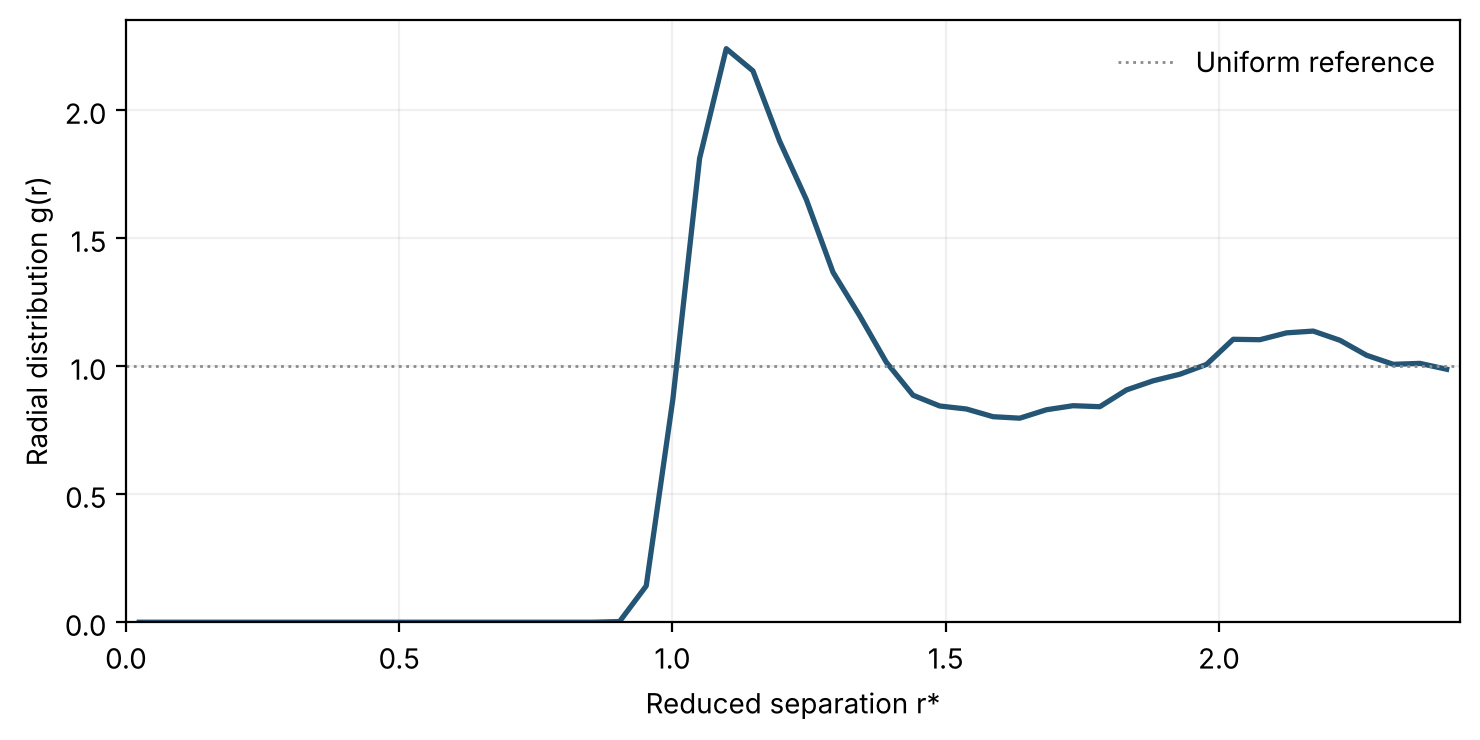

In [12]:
# Define radial bins only to half the box side.
edges = np.linspace(0.0, box_length/2, 51)
# Start one integer histogram count per shell.
pair_counts = np.zeros(len(edges)-1, dtype=int)
# Select only unordered pairs above the matrix diagonal.
upper = np.triu_indices(n_particles, k=1)
# Accumulate counts across the saved production snapshots.
for snapshot in production['snapshots']:
    # Form all pair displacements in this saved frame.
    differences = snapshot[:, None, :] - snapshot[None, :, :]
    # Apply the same nearest-image rule as in the force calculation.
    differences -= box_length * np.rint(differences / box_length)
    # Take square roots here because RDF binning needs actual distances.
    pair_distances = np.linalg.norm(differences[upper], axis=1)
    # Count unordered pair separations in each radial bin.
    pair_counts += np.histogram(pair_distances, bins=edges)[0]

# Compute exact volumes of the spherical histogram shells.
shell_volume = (4*math.pi/3) * (edges[1:]**3 - edges[:-1]**3)
# Calculate uniform-position reference counts for unordered pairs.
reference_per_frame = (n_particles*(n_particles-1)/2) * shell_volume/volume
# Normalize counts by frames and reference counts to obtain g(r).
g_r = pair_counts/(len(production['snapshots'])*reference_per_frame)
# Use bin midpoints as x coordinates for the plot.
r_mid = (edges[:-1]+edges[1:])/2
# Display a value students can inspect and compare.
print('Saved snapshots used:', len(production['snapshots']))
# Display a value students can inspect and compare.
print('Maximum g(r) near r* =', round(r_mid[np.argmax(g_r)], 3))

# Create or format the figure for this analysis.
fig, ax = plt.subplots(figsize=(7.5, 3.8))
# Plot the specified data series with a labelled visual style.
ax.plot(r_mid, g_r, color='#245575', linewidth=1.9)
# Create or format the figure for this analysis.
ax.axhline(1, color='#8b8b8b', linestyle=':', linewidth=1, label='Uniform reference')
# Label the axis or set its visible range.
ax.set(xlim=(0, box_length/2), xlabel='Reduced separation r*',
       # Complete the labelled plotting command on the preceding line.
       ylabel='Radial distribution g(r)')
# Label the axis or set its visible range.
ax.set_ylim(bottom=0)
# Identify the plotted curves in the figure.
ax.legend(frameon=False)
# Add light guides to support reading the values.
ax.grid(alpha=0.18)
# Prevent labels from colliding with panel edges.
fig.tight_layout()
# Display the completed figure in the notebook.
plt.show()


## 6. Motion across periodic boundaries

Wrapping coordinates back into $[0,L)$ conceals a crossing of the boundary. For the mean-squared displacement (MSD), we therefore kept an **unwrapped** position for each particle. Relative to the start of production,

$$\mathrm{MSD}(t)=\frac1N\sum_i|\mathbf R_i(t)-\mathbf R_i(0)|^2.$$

This is a **single-origin**, short-time descriptive curve. It shows the change in positions, not a reliable diffusion coefficient. Estimating long-time diffusion would require a longer run, suitable time origins, an identified diffusive regime, and statistical checks. A rise at early time is not by itself evidence of diffusion.


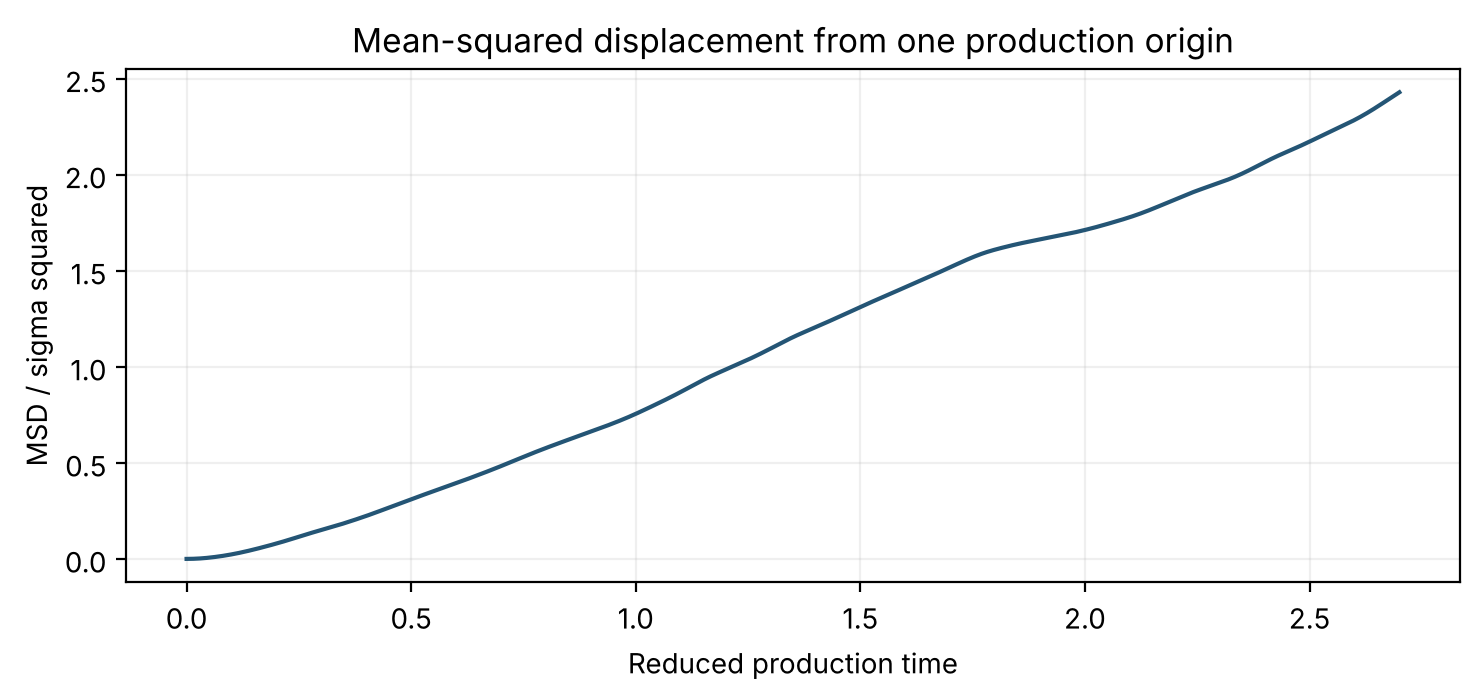

In [13]:
# Create one panel for the displacement history.
fig, ax = plt.subplots(figsize=(7.5, 3.6))
# Plot average squared displacement measured from the production origin.
ax.plot(production['time'], production['MSD'], color='#245575')
# State that the horizontal coordinate is reduced production time.
ax.set(xlabel='Reduced production time', ylabel='MSD / sigma squared',
       # Explain in the title that this is a single-origin estimate.
       title='Mean-squared displacement from one production origin')
# Add light guides for reading the displacement scale.
ax.grid(alpha=0.2)
# Fit the title and axes within the figure margins.
fig.tight_layout()
# Display the mean-squared-displacement diagnostic.
plt.show()


## 7. Numerical and reproducibility checks

The prepared state is held fixed in the following comparison. We run the production period once at the original step $\Delta t$ and again at $\Delta t/2$ for approximately the same physical time. Both starts are copies of the same arrays. This is a **time-step sensitivity check** on one prepared state, not a claim of full convergence. We also repeat the baseline production call to verify identical arrays in the same Python environment.


In [14]:
# Repeat the baseline from copies of the same prepared state.
repeat = production_run(prepared_state, time_step, production_steps)
# Halve the time increment for a sensitivity comparison.
half_step = production_run(prepared_state, time_step/2,
                           # Double the number of steps to preserve final physical time.
                           production_steps*2, sample_every=20)

# Name the energy-drift calculation so both runs use one definition.
def energy_deviation_percent(data):
    # Take the first energy of this particular run as its reference.
    first = data['E'][0]
    # Compute normalized maximum deviation across the whole run.
    return 100*np.max(np.abs(data['E']-first))/max(abs(first), 1.0)

# Check every baseline energy value, not just a rounded summary.
same_energy_history = np.array_equal(production['E'], repeat['E'])
# Display whether the two complete energy trajectories match exactly.
print('Complete baseline energy history reproduced:', same_energy_history)
# Label the maximum baseline energy-deviation diagnostic.
print('Baseline maximum E deviation (%):',
      # Format the baseline deviation as a percentage.
      f'{energy_deviation_percent(production):.5f}')
# Label the corresponding half-time-step deviation.
print('Half-step maximum E deviation (%):',
      # Format the half-step deviation on the same percentage scale.
      f'{energy_deviation_percent(half_step):.5f}')
# Show that doubling steps compensates for halving their duration.
print('Final times:', production['time'][-1], half_step['time'][-1])
# Fail immediately if a nominal repeat differs.
assert same_energy_history
# Verify that the compared trajectories span equal durations.
assert abs(production['time'][-1]-half_step['time'][-1]) < 1e-12
# Reject any run containing nonfinite energy values.
assert np.isfinite(production['E']).all() and np.isfinite(half_step['E']).all()


Complete baseline energy history reproduced: True
Baseline maximum E deviation (%): 0.01306
Half-step maximum E deviation (%): 0.00434
Final times: 2.7 2.7


## Questions to work through

1. **Arrays and indices.** What are the shapes of `initial_positions`, `displacement`, and `pair_force`? What does entry `[i, j]` mean? Why must the diagonal be excluded?
2. **Conditions.** Locate three uses of `if`: protection against overlap, periodic velocity rescaling, and snapshot selection. What is the purpose of each?
3. **Counting pairs.** How many distinct unordered pairs exist for $N=64$? Why does the potential energy contain a factor of $1/2$ but the force on particle $i$ does not?
4. **Newton's laws.** In the finite-difference test, why should the numerical derivative have a minus sign? Why do pair forces sum to zero?
5. **Experimental design.** What data belong to preparation and what data belong to production? Why would including the rescaling stage in an energy-conservation calculation be misleading?
6. **Statistics.** Compare the five block means with the overall mean. Why are five blocks insufficient for a trustworthy confidence interval?
7. **Interpretation.** How do the first peak of $g(r)$ and the MSD curve answer different questions? Why can neither establish a phase or a diffusion coefficient from this notebook alone?
8. **Extension.** Change the random seed, then run from the top. Distinguish a changed initial condition from a changed force model. Compare the same diagnostics rather than only the final plot.

Keep the original values when sharing the worked example, or record every setting you change. If an edited run triggers the close-contact error, reduce the time step or reconsider the initial configuration rather than removing the check.


## Scope, limitations, and sources

This finite system is a pedagogical model. Preparation by occasional velocity rescaling is not a rigorous canonical thermostat. Production is unthermostatted and approximates a constant-energy trajectory at fixed volume and particle number. The shifted-force cutoff changes the interaction, and no long-range correction is applied. A single short trajectory with correlated measurements cannot establish equilibrium pressure, an equation of state, a phase, or a diffusion coefficient. The RDF and pressure estimates are included to teach how data structures, numerical simulation and statistical summaries fit together.

The formulas and implementation choices may be compared with the official [LAMMPS force-shifted Lennard-Jones documentation](https://docs.lammps.org/pair_lj_smooth_linear.html), [LAMMPS velocity-Verlet NVE documentation](https://docs.lammps.org/fix_nve.html), [LAMMPS pressure/virial documentation](https://docs.lammps.org/compute_pressure.html), and [LAMMPS RDF documentation](https://docs.lammps.org/compute_rdf.html). For the programming trade-offs, consult the [LAMMPS pair-force example using squared separation](https://docs.lammps.org/pair_python.html), [LAMMPS neighbour-list explanation](https://docs.lammps.org/stable/Developer_par_neigh.html), and [NumPy broadcasting guidance](https://numpy.org/doc/stable/user/basics.broadcasting.html). This small Python program is independent of LAMMPS and is intended to expose the calculations clearly, not to replace production MD software.
